# 02 · Seleção de atributos e modelagem

Estratégia de avaliação, fixada antes de treinar:

- **Divisão cronológica**, porque é uma série temporal e o modelo será usado para prever o futuro:
  treino 2010–2022, validação 2023–2024 e teste de 2025 até o último dia disponível.
  Uma divisão aleatória misturaria dias vizinhos (muito parecidos) entre treino e teste e daria um resultado otimista.
- **Métrica principal: MAE** (erro absoluto médio, em °C), fácil de explicar: "o modelo erra em média X graus".
- **Referências ingênuas**: persistência (amanhã = hoje) e climatologia (média histórica da época do ano).
- **Seleção de atributos por votação** de três métodos, ajustados só com o treino.
- **Hiperparâmetros** com validação cruzada temporal (`TimeSeriesSplit`, 5 dobras) só dentro do treino.
- **Escolha** do algoritmo e do conjunto de atributos pelo menor MAE na validação.
- O **teste** é usado uma única vez, no notebook 03.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src import config, features, modelagem

pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
config.FIGURAS.mkdir(parents=True, exist_ok=True)
import json
import joblib
import sklearn
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from src import selecao

In [2]:
dataset = features.preparar(features.carregar())
treino, validacao, teste = features.dividir(dataset)
candidatas = features.lista_atributos(dataset)
print(f"{len(candidatas)} atributos candidatos")
pd.DataFrame({nome: {"início": p.index.min().date(), "fim": p.index.max().date(), "dias": len(p),
                     "máxima média (°C)": round(p.alvo.mean(), 1)}
              for nome, p in [("treino", treino), ("validação", validacao), ("teste", teste)]}).T

29 atributos candidatos


,início,fim,dias,máxima média (°C)
treino,2010-01-07,2022-12-31,4742,24.5
validação,2023-01-01,2024-12-31,731,25.3
teste,2025-01-01,2026-11-16,685,24.2


## Referências ingênuas

Um modelo só tem valor se for melhor que regras simples.

In [3]:
resultados = {}
for nome, ref in [("Persistência (amanhã = hoje)", modelagem.Persistencia()),
                  ("Climatologia (média da época)", modelagem.Climatologia())]:
    ref.fit(treino[candidatas], treino.alvo)
    resultados[nome] = modelagem.metricas(validacao.alvo, ref.predict(validacao[candidatas]))
pd.DataFrame(resultados).T

,mae,rmse,r2,erro_ate_2c,erro_max
Persistência (amanhã = hoje),2.769,3.656,0.340,0.486,14.200
Climatologia (média da época),3.189,3.945,0.232,0.367,11.782


## Seleção de atributos por votação

Três métodos com "visões" diferentes votam nos seus 10 melhores atributos, olhando **só o treino**:

| Método | O que mede |
|:--|:--|
| **SelectKBest** (teste F) | relação linear de cada atributo, isolado, com o alvo |
| **Random Forest** | importância num modelo não linear que vê os atributos juntos |
| **RFE** com Ridge | elimina, um a um, o atributo de menor peso num modelo linear |

Entra quem tiver **pelo menos 2 dos 3 votos** (maioria).

In [4]:
ranking = selecao.tres_metodos(treino, candidatas)
votos, eleitas = selecao.votar(ranking)
print(f"eleitas ({len(eleitas)}):", ", ".join(eleitas))
votos[["rank_kbest", "rank_rf", "rank_rfe", "voto_kbest", "voto_rf", "voto_rfe", "votos", "eleita"]]

eleitas (7): tmed, dia_ano_cos, tmin, vento_dir_cos, radiacao, tmax, evapotranspiracao


,rank_kbest,rank_rf,rank_rfe,voto_kbest,voto_rf,voto_rfe,votos,eleita
tmed,1.0,1.0,2.0,True,True,True,3,True
dia_ano_cos,7.0,4.0,5.0,True,True,True,3,True
tmin,4.0,6.0,14.0,True,True,False,2,True
vento_dir_cos,14.0,3.0,7.0,False,True,True,2,True
radiacao,9.0,13.0,4.0,True,False,True,2,True
tmax,2.0,2.0,26.0,True,True,False,2,True
evapotranspiracao,8.0,26.0,6.0,True,False,True,2,True
tmax_media7,6.0,16.0,11.0,True,False,False,1,False
orvalho,3.0,11.0,20.0,True,False,False,1,False
pressao_delta1,15.0,8.0,12.0,False,True,False,1,False


Os três métodos concordam nas temperaturas do dia e na época do ano. Atributos como os *lags* e as médias móveis
ficam de fora porque são **redundantes** com `tmax`, `tmin` e `tmed` (muito correlacionados entre si): cada método prefere um
representante do grupo. A pergunta é se essa versão enxuta perde informação útil, e isso é medido na validação abaixo.

## Busca de hiperparâmetros (validação cruzada temporal no treino)

Cada algoritmo é ajustado duas vezes: com **todos os atributos** e só com os **eleitos pela votação**.

In [5]:
cv = TimeSeriesSplit(n_splits=5)
conjuntos = {"todos": candidatas, "votação": eleitas}
melhores, previsoes_validacao = {}, {}
for nome, pipeline in modelagem.candidatos().items():
    for nome_conjunto, colunas in conjuntos.items():
        busca = GridSearchCV(pipeline, modelagem.GRADES[nome], cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
        busca.fit(treino[colunas], treino.alvo)
        chave = f"{nome} · {nome_conjunto}"
        melhores[chave] = (busca.best_estimator_, colunas)
        previsoes_validacao[chave] = busca.best_estimator_.predict(validacao[colunas])
        resultados[chave] = modelagem.metricas(validacao.alvo, previsoes_validacao[chave])
        print(f"{chave:36s} MAE CV = {-busca.best_score_:.3f}  {busca.best_params_}")

Ridge · todos                        MAE CV = 1.917  {'modelo__alpha': 10.0}
Ridge · votação                      MAE CV = 2.073  {'modelo__alpha': 1.0}


Random Forest · todos                MAE CV = 1.931  {'modelo__max_depth': None, 'modelo__min_samples_leaf': 5}


Random Forest · votação              MAE CV = 2.048  {'modelo__max_depth': 12, 'modelo__min_samples_leaf': 5}


HistGradientBoosting · todos         MAE CV = 1.863  {'modelo__learning_rate': 0.03, 'modelo__max_leaf_nodes': 15}


HistGradientBoosting · votação       MAE CV = 2.044  {'modelo__learning_rate': 0.03, 'modelo__max_leaf_nodes': 7}


## Comparação na validação (2023–2024)

In [6]:
tabela_validacao = pd.DataFrame(resultados).T.sort_values("mae")
tabela_validacao.style.highlight_min(subset=["mae", "rmse", "erro_max"], color="#fdd").highlight_max(
    subset=["r2", "erro_ate_2c"], color="#fdd").format("{:.3f}")

,mae,rmse,r2,erro_ate_2c,erro_max
HistGradientBoosting · todos,1.989,2.600,0.666,0.610,9.261
Ridge · todos,2.069,2.657,0.652,0.572,9.460
Random Forest · todos,2.070,2.679,0.646,0.587,9.512
HistGradientBoosting · votação,2.252,2.891,0.587,0.544,9.140
Random Forest · votação,2.254,2.879,0.591,0.543,9.208
Ridge · votação,2.267,2.882,0.590,0.529,9.688
Persistência (amanhã = hoje),2.769,3.656,0.340,0.486,14.200
Climatologia (média da época),3.189,3.945,0.232,0.367,11.782


escolhido: HistGradientBoosting · todos | MAE 1.989 °C, 28% menor que a persistência


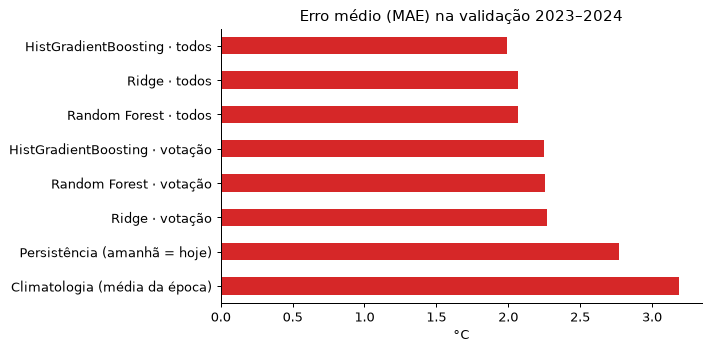

In [7]:
escolhido = min(melhores, key=lambda n: resultados[n]["mae"])
modelo_validacao, atributos = melhores[escolhido]
pers = resultados["Persistência (amanhã = hoje)"]["mae"]
print(f"escolhido: {escolhido} | MAE {resultados[escolhido]['mae']:.3f} °C, "
      f"{1 - resultados[escolhido]['mae'] / pers:.0%} menor que a persistência")

ax = tabela_validacao["mae"].sort_values(ascending=False).plot.barh(figsize=(8, 4), color="tab:red")
ax.set(title="Erro médio (MAE) na validação 2023–2024", xlabel="°C")
plt.tight_layout()
plt.savefig(config.FIGURAS / "02_comparacao.png", bbox_inches="tight")
plt.show()

**Resultado da votação:** com menos atributos o modelo fica mais simples, mas o erro **aumenta** em todos os algoritmos.
A informação descartada (variação da pressão, médias recentes, nuvens) ajuda justamente nos dias de mudança de tempo, que são
os mais difíceis. Por isso o modelo final usa **todos os atributos**: a seleção foi testada e rejeitada com base em evidência,
não por preferência.

## Faixa de erro da previsão

Além do valor previsto, a demonstração mostra uma faixa onde a máxima real deve cair em ~80% dos dias. Ela vem dos
**resíduos na validação** (real − previsto): o 10º e o 90º percentis.

faixa de 80%: de -2.9 °C a +3.6 °C em torno da previsão


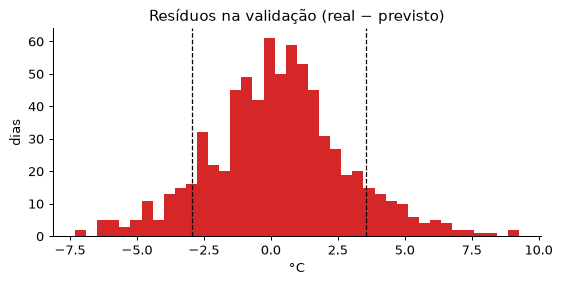

In [8]:
residuos = validacao.alvo - previsoes_validacao[escolhido]
faixa = modelagem.intervalo(residuos, 0.8)
print(f"faixa de 80%: de {faixa[0]:+.1f} °C a {faixa[1]:+.1f} °C em torno da previsão")
fig, ax = plt.subplots(figsize=(7, 3))
residuos.clip(-10, 10).plot.hist(bins=40, ax=ax, color="tab:red")
for v in faixa:
    ax.axvline(v, color="k", ls="--", lw=1)
ax.set(title="Resíduos na validação (real − previsto)", xlabel="°C", ylabel="dias")
plt.savefig(config.FIGURAS / "02_residuos.png", bbox_inches="tight")
plt.show()

## Treino final e modelo salvo

Com o algoritmo, os hiperparâmetros e os atributos escolhidos, o modelo é **retreinado com treino + validação** (2010–2024),
para aproveitar os dois anos mais recentes antes de ser avaliado no teste e usado na demonstração.

In [9]:
final = sklearn.base.clone(modelo_validacao)
desenvolvimento = pd.concat([treino, validacao])
final.fit(desenvolvimento[atributos], desenvolvimento.alvo)

pacote = {"modelo": final, "nome": escolhido.split(" · ")[0], "atributos": atributos, "faixa_80": faixa,
          "treinado_ate": str(desenvolvimento.index.max().date()), "versao_sklearn": sklearn.__version__}
config.MODELO.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(pacote, config.MODELO, compress=3)
votos.to_csv(RAIZ / "reports" / "votacao_atributos.csv", index_label="atributo")

resumo = {"escolhido": escolhido, "faixa_80": faixa, "atributos_eleitos_votacao": eleitas,
          "parametros": {k: str(v) for k, v in modelo_validacao.named_steps["modelo"].get_params().items()},
          "validacao": tabela_validacao.round(4).to_dict(orient="index")}
(RAIZ / "reports" / "metricas_validacao.json").write_text(json.dumps(resumo, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"modelo salvo em models/{config.MODELO.name} ({config.MODELO.stat().st_size / 1e6:.2f} MB)")

modelo salvo em models/modelo_tmax.joblib (0.23 MB)
